In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from energia.dataset import cargar_datos_modelo

from energia.entrenamiento import (fijar_semilla,dispositivo,contar_parametros,entrenar,predecir,guardar_modelo,guardar_resultados,)
from energia.metricas import (evaluar,error_por_hora,naive_estacional,tabla,)
from energia.modelos import gru
from energia.visualizacion import (estilo,guardar_figura,curvas_aprendizaje,pronostico_vs_real,)

estilo()
NOMBRE = "gru"
fijar_semilla()

print("PyTorch:", torch.__version__)
print("Dispositivo:", dispositivo())
print("Modelo:", NOMBRE)


PyTorch: 2.5.1+cpu
Dispositivo: cpu
Modelo: gru


In [2]:
datos = cargar_datos_modelo()
display(datos.resumen())

,muestras,pasado,futuro,y,primer_t0,ultimo_t0
split,,,,,,
train,30265,"(30265, 168, 16)","(30265, 24, 9)","(30265, 24, 2)",2022-01-16,2025-06-30
val,184,"(184, 168, 16)","(184, 24, 9)","(184, 24, 2)",2025-07-01,2025-12-31
test,243,"(243, 168, 16)","(243, 24, 9)","(243, 24, 2)",2026-01-01,2026-08-31


In [3]:
# VERIFICACIÓN DE DATOS
# Dimensiones oficiales del problema
assert datos.ventana == 168
assert datos.horizonte == 24
assert len(datos.columnas_pasado) == 16
assert len(datos.columnas_futuro) == 9
assert len(datos.columnas_objetivo) == 2

# Orden requerido por nuestra arquitectura GRU
assert datos.columnas_objetivo == ["demanda_kwh","precio_bolsa_cop_kwh",]

assert datos.columnas_pasado[:2] == datos.columnas_objetivo

# Consistencia de las particiones
for nombre in ("train", "val", "test"):
    particion = datos.splits[nombre]
    assert particion.pasado.shape[1:] == (168, 16)
    assert particion.futuro.shape[1:] == (24, 9)
    assert particion.y.shape[1:] == (24, 2)
    assert (len(particion.pasado)== len(particion.futuro)== len(particion.y))

print("Verificación de dimensiones: correcta")
print("Verificación de particiones: correcta")
print("Orden de objetivos: correcto")

print("\nVariables objetivo:")
print(datos.columnas_objetivo)

print("\nVariables históricas:")
print(datos.columnas_pasado)

print("\nVariables futuras:")
print(datos.columnas_futuro)


Verificación de dimensiones: correcta
Verificación de particiones: correcta
Orden de objetivos: correcto

Variables objetivo:
['demanda_kwh', 'precio_bolsa_cop_kwh']

Variables históricas:
['demanda_kwh', 'precio_bolsa_cop_kwh', 'precio_contrato_cop_kwh', 'aportes_kwh_d1', 'aportes_media7_kwh_d1', 'volumen_util_kwh_d1', 'volumen_util_delta7_kwh_d1', 'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos', 'dia_anio_sin', 'dia_anio_cos', 'es_festivo', 'es_sabado', 'es_domingo_o_festivo']

Variables futuras:
['hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos', 'dia_anio_sin', 'dia_anio_cos', 'es_festivo', 'es_sabado', 'es_domingo_o_festivo']


In [4]:
# CONSTRUCCIÓN DE LA ARQUITECTURA GRU
# Hiperparámetros de la arquitectura
HP_MODELO = gru.HIPERPARAMETROS.copy()
# Hiperparámetros oficiales de entrenamiento
HP_ENTRENAMIENTO = {"optimizador": "adam","lr": 1e-3,"epocas": 50,"batch": 256,"paciencia": 8,"clip": 1.0,}
# Construcción del modelo
modelo = gru.construir(datos, **HP_MODELO)
print(modelo)
print("\nParámetros entrenables:", contar_parametros(modelo))
print("\nHiperparámetros del modelo:", HP_MODELO)
print("\nHiperparámetros de entrenamiento:", HP_ENTRENAMIENTO)

GRUPronostico(
  (gru): GRU(16, 48, num_layers=2, batch_first=True, dropout=0.15)
  (consulta): Linear(in_features=57, out_features=32, bias=True)
  (clave): Linear(in_features=48, out_features=32, bias=False)
  (cabeza): Sequential(
    (0): Linear(in_features=109, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.15, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)

Parámetros entrenables: 34178

Hiperparámetros del modelo: {'oculto': 48, 'capas': 2, 'dropout': 0.15, 'atencion': 32, 'cabeza': 64}

Hiperparámetros de entrenamiento: {'optimizador': 'adam', 'lr': 0.001, 'epocas': 50, 'batch': 256, 'paciencia': 8, 'clip': 1.0}


In [ ]:
# ENTRENAMIENTO DE LA GRU
historial = entrenar(modelo, datos, **HP_ENTRENAMIENTO)
# Resumen del entrenamiento
mejor_epoca = int(historial["val"].idxmin())
mejor_perdida = float(historial["val"].min())

print("\nEntrenamiento finalizado")
print("Épocas ejecutadas:", len(historial))
print("Mejor época:", mejor_epoca)
print("Mejor pérdida de validación:", mejor_perdida)

# Verificar los pesos restaurados de la mejor época
modelo.eval()

val = datos.splits["val"]
disp = next(modelo.parameters()).device

with torch.no_grad():
    pasado_val = torch.from_numpy(val.pasado).to(disp)
    futuro_val = torch.from_numpy(val.futuro).to(disp)
    y_val = torch.from_numpy(val.y).to(disp)
    pred_val_escalada = modelo(pasado_val, futuro_val)
    mse_verificada = torch.nn.functional.mse_loss(pred_val_escalada, y_val).item()
diferencia = abs(mse_verificada - mejor_perdida)

print("\nVerificación del entrenamiento")
print(f"MSE mejor época: {mejor_perdida:.8f}")
print(f"MSE reproducida: {mse_verificada:.8f}")
print(f"Diferencia:       {diferencia:.8f}")

assert diferencia < 1e-4, ("Los pesos no reproducen la mejor pérdida de validación.")

print("Verificación correcta: pesos y entrenamiento coherentes.")
hiperparametros = {"modelo": HP_MODELO,"entrenamiento": HP_ENTRENAMIENTO,}
ruta_modelo = guardar_modelo(modelo, NOMBRE, hiperparametros)
print("Modelo guardado en:", ruta_modelo)

época   1 | train 0.1856 | val 0.1771 |  27.5 s *
época   2 | train 0.1000 | val 0.1412 |  28.1 s *
época   3 | train 0.0855 | val 0.1304 |  28.2 s *
época   4 | train 0.0781 | val 0.1218 |  27.9 s *
época   5 | train 0.0736 | val 0.1192 |  31.7 s *
época   6 | train 0.0702 | val 0.1199 |  39.9 s
época   7 | train 0.0678 | val 0.1168 |  44.0 s *
época   8 | train 0.0655 | val 0.1164 |  42.4 s *
época   9 | train 0.0634 | val 0.1174 |  41.3 s
época  10 | train 0.0614 | val 0.1212 |  41.2 s
época  11 | train 0.0597 | val 0.1177 |  41.5 s
época  12 | train 0.0577 | val 0.1220 |  47.0 s
época  13 | train 0.0557 | val 0.1274 |  45.8 s
época  14 | train 0.0544 | val 0.1273 |  49.4 s
época  15 | train 0.0525 | val 0.1323 |  44.3 s
época  16 | train 0.0510 | val 0.1395 |  42.0 s
Early stopping: 8 épocas sin mejorar en validación.

Entrenamiento finalizado
Épocas ejecutadas: 16
Mejor época: 8
Mejor pérdida de validación: 0.1164153590798378

Verificación del entrenamiento
MSE mejor época: 0.1164

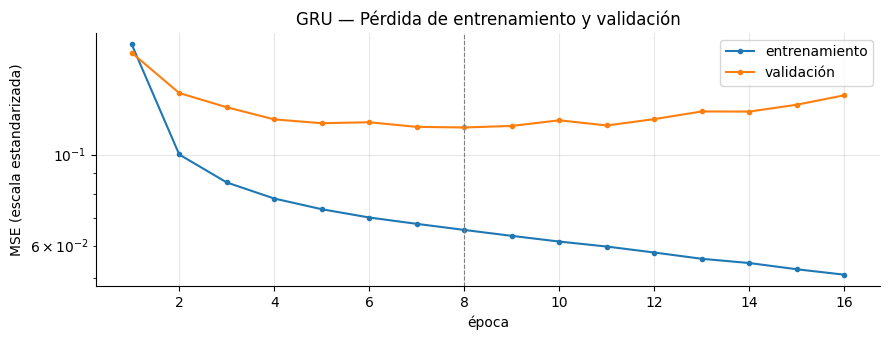

Mejor época: 8
MSE mínimo de validación: 0.116415


In [6]:
# CURVAS DE APRENDIZAJE DE LA GRU
fig = curvas_aprendizaje(historial,titulo="GRU — Pérdida de entrenamiento y validación")
guardar_figura(fig, "f2_03_gru_aprendizaje")
plt.show()
print(f"Mejor época: {mejor_epoca}")
print(f"MSE mínimo de validación: {historial['val'].min():.6f}")

In [7]:
# Predicciones en unidades originales (kWh y COP/kWh)
pred_val = predecir(modelo, datos, "val")
real_val = datos.y_original("val")

# Líneas base oficiales
naive_diario = naive_estacional(datos, "val", m=24)
naive_semanal = naive_estacional(datos, "val", m=168)

# Métricas de validación
metricas_val = tabla({
    "GRU": evaluar(real_val, pred_val),
    "Naive diario": evaluar(real_val, naive_diario),
    "Naive semanal": evaluar(real_val, naive_semanal),})

display(metricas_val.round(3))
print("\nMAPE de nuestra GRU:")
print(f"Demanda: {metricas_val.loc['GRU', 'demanda_MAPE_%']:.4f}%")
print(f"Precio:  {metricas_val.loc['GRU', 'precio_MAPE_%']:.4f}%")


,demanda_MAE,precio_MAE,demanda_RMSE,precio_RMSE,demanda_MAPE_%,precio_MAPE_%,demanda_R2,precio_R2
GRU,59901.295,48.974,82336.053,96.745,2.001,21.695,0.903,0.608
Naive diario,194135.892,48.524,274407.867,111.795,6.719,20.337,-0.076,0.476
Naive semanal,111762.366,81.735,179377.524,136.077,3.833,37.449,0.540,0.224



MAPE de nuestra GRU:
Demanda: 2.0007%
Precio:  21.6952%


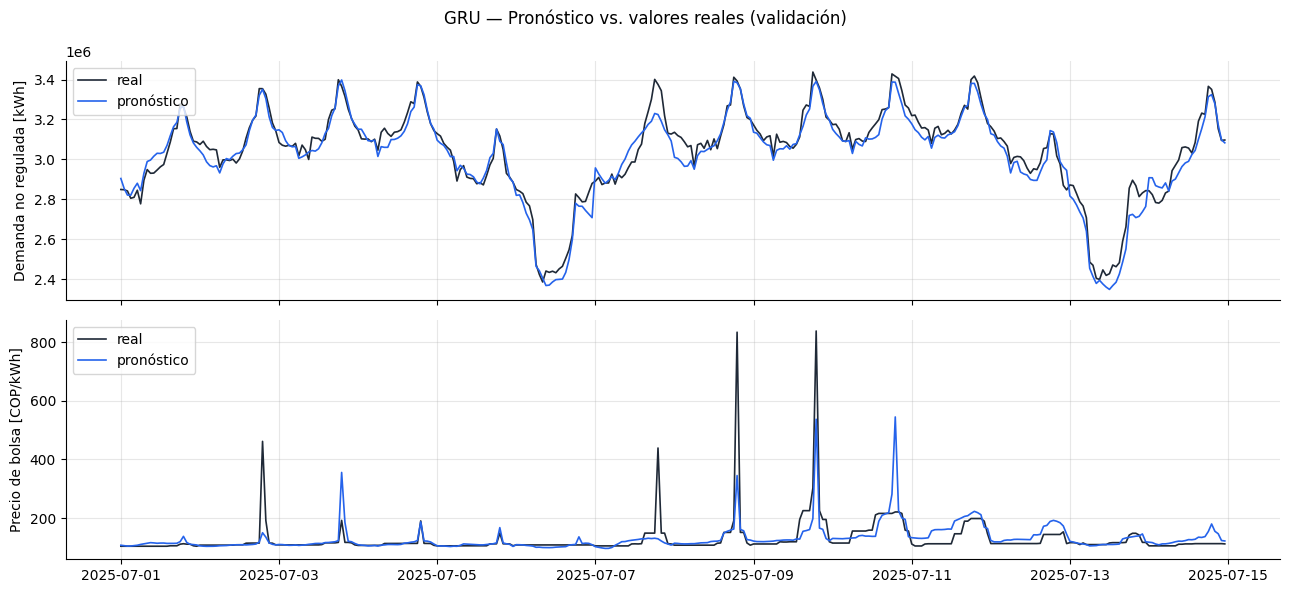

In [8]:
# PRONÓSTICO VS. VALORES REALES — VALIDACIÓN
fig = pronostico_vs_real(datos,pred_val,split="val",dias=14,desde=0,titulo="GRU — Pronóstico vs. valores reales (validación)")
guardar_figura(fig, "f2_03_gru_pronostico_val")
plt.show()

In [9]:
# PREDICCIONES EN UNIDADES ORIGINALES 
pred_test = predecir(modelo, datos, "test")
real_test = datos.y_original("test")

In [10]:
# MÉTRICAS DE PRUEBA — 2026
metricas_test = tabla({
    "GRU": evaluar(real_test, pred_test),
    "Naive diario": evaluar(
        real_test, naive_estacional(datos, "test", m=24)),
    "Naive semanal": evaluar(
        real_test, naive_estacional(datos, "test", m=168)),})

display(metricas_test.round(3))

print("\nMAPE de la GRU en prueba 2026:")
print(f"Demanda: {metricas_test.loc['GRU', 'demanda_MAPE_%']:.4f}%")
print(f"Precio:  {metricas_test.loc['GRU', 'precio_MAPE_%']:.4f}%")

,demanda_MAE,precio_MAE,demanda_RMSE,precio_RMSE,demanda_MAPE_%,precio_MAPE_%,demanda_R2,precio_R2
GRU,67009.887,72.149,91279.719,114.195,2.230,16.883,0.896,0.874
Naive diario,194816.646,56.110,273062.871,111.123,6.671,14.863,0.069,0.881
Naive semanal,121128.936,126.488,201826.283,182.249,4.060,34.665,0.492,0.680



MAPE de la GRU en prueba 2026:
Demanda: 2.2296%
Precio:  16.8830%


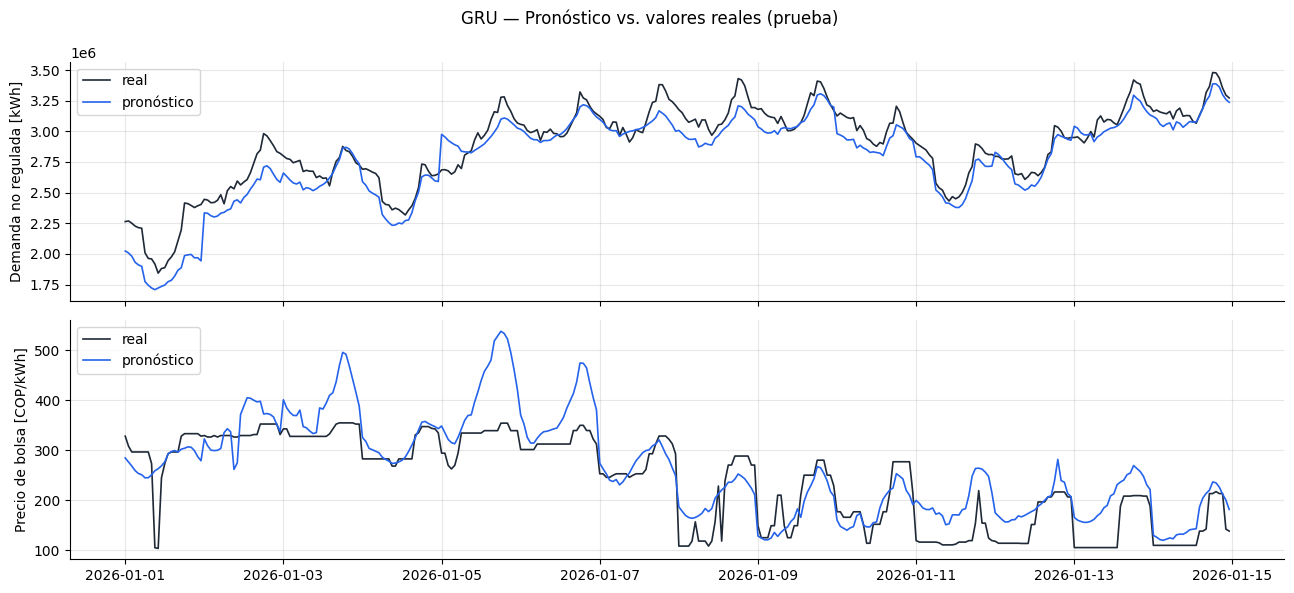

In [11]:
# PRONÓSTICO VS. VALORES REALES — PRUEBA
fig = pronostico_vs_real(datos, pred_test, split="test", dias=14, desde=0,titulo="GRU — Pronóstico vs. valores reales (prueba)")
guardar_figura(fig, "f2_03_gru_pronostico_test")
plt.show()

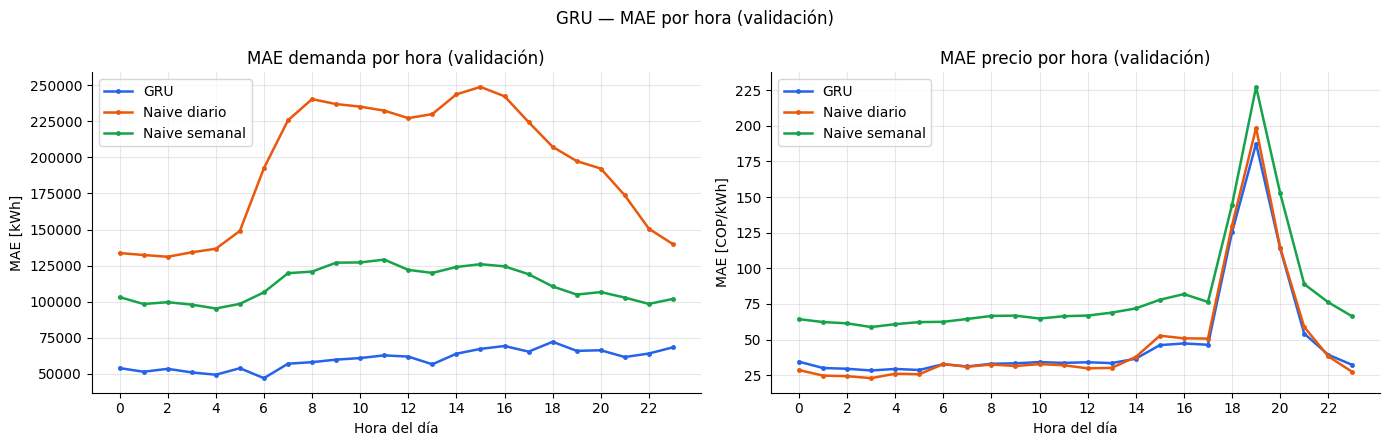

In [12]:
# ERROR ABSOLUTO MEDIO POR HORA — VALIDACIÓN
errores_horarios = {
    "GRU": error_por_hora(real_val, pred_val),
    "Naive diario": error_por_hora(real_val, naive_diario),
    "Naive semanal": error_por_hora(real_val, naive_semanal),}

colores = { "GRU": "#2563eb","Naive diario": "#ea580c","Naive semanal": "#16a34a",}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

variables = [("demanda", "MAE demanda por hora (validación)", "kWh"),("precio", "MAE precio por hora (validación)", "COP/kWh"),]

for ax, (variable, titulo, unidad) in zip(axes, variables):

    for nombre, errores in errores_horarios.items():
        ax.plot(
            errores.index - 1,
            errores[variable],
            label=nombre,
            color=colores[nombre],
            linewidth=1.8,
            marker=".",
            markersize=5,)

    ax.set_title(titulo)
    ax.set_xlabel("Hora del día")
    ax.set_ylabel(f"MAE [{unidad}]")
    ax.set_xticks(range(0, 24, 2))
    ax.legend()

fig.suptitle("GRU — MAE por hora (validación)")
fig.tight_layout()

guardar_figura(fig, "f2_03_gru_error_por_hora")
plt.show()

In [13]:
# CONSOLIDACIÓN DE MÉTRICAS — VALIDACIÓN Y PRUEBA
nombres = {"GRU": NOMBRE,"Naive diario": "naive_m24","Naive semanal": "naive_m168",}
# Unificar los resultados ya calculados
metricas = pd.concat(
    {"val": metricas_val.rename(index=nombres),"test": metricas_test.rename(index=nombres),},names=["split", "modelo"],)
# Mantener el mismo índice que los compañeros:
# (modelo, split)
metricas = metricas.swaplevel("split", "modelo").sort_index()
print("MÉTRICAS COMPLETAS — GRU Y LÍNEAS BASE")
display(metricas.round(3))
# Resumen usado para la selección en fase 2
print("\nRESUMEN DE VALIDACIÓN — CRITERIO DE SELECCIÓN")
columnas = ["demanda_MAPE_%","precio_MAPE_%","demanda_MAE","precio_MAE",]

display(metricas.loc[(slice(None), "val"),columnas].round(3))


MÉTRICAS COMPLETAS — GRU Y LÍNEAS BASE


demanda_MAE  precio_MAE  demanda_RMSE  precio_RMSE  \
modelo     split                                                       
gru        test     67009.887      72.149     91279.719      114.195   
           val      59901.295      48.974     82336.053       96.745   
naive_m168 test    121128.936     126.488    201826.283      182.249   
           val     111762.366      81.735    179377.524      136.077   
naive_m24  test    194816.646      56.110    273062.871      111.123   
           val     194135.892      48.524    274407.867      111.795   

                  demanda_MAPE_%  precio_MAPE_%  demanda_R2  precio_R2  
modelo     split                                                        
gru        test            2.230         16.883       0.896      0.874  
           val             2.001         21.695       0.903      0.608  
naive_m168 test            4.060         34.665       0.492      0.680  
           val             3.833         37.449       0.540      0.224  
naive_m24  test            6.671         14.863       0.069      0.881  
           val             6.719         20.337      -0.076      0.476


RESUMEN DE VALIDACIÓN — CRITERIO DE SELECCIÓN


,,demanda_MAPE_%,precio_MAPE_%,demanda_MAE,precio_MAE
modelo,split,,,,
gru,val,2.001,21.695,59901.295,48.974
naive_m168,val,3.833,37.449,111762.366,81.735
naive_m24,val,6.719,20.337,194135.892,48.524


In [14]:
# GUARDAR — GRU
import math
from energia import config
# Verificar la estructura oficial de las métricas
assert isinstance(metricas.index, pd.MultiIndex)
assert metricas.index.names == ["modelo", "split"]
filas_esperadas = {(nombre, split)for nombre in (NOMBRE, "naive_m24", "naive_m168")for split in ("val", "test")}
assert set(metricas.index.tolist()) == filas_esperadas, ("La tabla de métricas está incompleta.")

# Comprobar que las métricas corresponden al modelo actual
for split in ("val", "test"):
    reales = datos.y_original(split)
    predichos = predecir(modelo, datos, split)
    resultados = evaluar(reales, predichos)
    for indicador, obtenido in resultados.items():
        registrado = float( metricas.loc[(NOMBRE, split), indicador])
        assert math.isclose(float(obtenido),registrado,rel_tol=1e-6,abs_tol=1e-4,), f"Inconsistencia en {split}: {indicador}"

print("Métricas verificadas: validación y prueba.")
# Verificar el checkpoint guardado tras el entrenamiento
checkpoint = torch.load(config.MODELOS / f"{NOMBRE}.pt",map_location="cpu",weights_only=True,)
for nombre, parametro in modelo.state_dict().items():
    assert torch.equal(parametro.detach().cpu(),checkpoint["estado"][nombre],), f"Los pesos guardados no coinciden: {nombre}"

print("Checkpoint verificado: pesos coincidentes.")
# Registrar la configuración experimental
hiperparametros_final = {"modelo": HP_MODELO,"entrenamiento": HP_ENTRENAMIENTO,"parametros_entrenables": contar_parametros(modelo),"mejor_epoca": int(historial["val"].idxmin()),"epocas_ejecutadas": len(historial),"tiempo_total_segundos": float(historial["segundos"].sum()),}

# Guardar únicamente después de las verificaciones
ruta_modelo = guardar_modelo(modelo, NOMBRE, hiperparametros_final)
ruta_resultados = guardar_resultados(NOMBRE, metricas, hiperparametros_final, historial)
print("\nGUARDADO OFICIAL COMPLETADO")
print("Modelo:", ruta_modelo)
print("Resultados:", ruta_resultados)
print("Filas de métricas:", len(metricas))
print("Épocas registradas:", len(historial))

Métricas verificadas: validación y prueba.
Checkpoint verificado: pesos coincidentes.

GUARDADO OFICIAL COMPLETADO
Modelo: C:\Users\SARA ISABEL\Documents\UNIVERSIDAD\2026-2\TrabajodeOpIA\pronostico-energia-nr\results\modelos\gru.pt
Resultados: C:\Users\SARA ISABEL\Documents\UNIVERSIDAD\2026-2\TrabajodeOpIA\pronostico-energia-nr\results\fase2\gru
Filas de métricas: 6
Épocas registradas: 16
